# Llama 3 DC-PMI on MR-GSM8K

Sample `question_type=original` examples from `Randolphzeng/Mr-GSM8K` and compare three step-level DC-PMI context ablations under `meta-llama/Meta-Llama-3-8B-Instruct`.

In [1]:
%load_ext autoreload
%autoreload 2
print("Loaded kernel extensions")

Loaded kernel extensions


In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from huggingface_hub import login
from IPython.display import display, Markdown
from transformers import AutoTokenizer

In [3]:
from plots import align_first_error_steps, plot_first_error_roc, plot_first_error_trajectories
from score_dc_pmi import (
    DEFAULT_DATASET_ID,
    DEFAULT_MODEL_ID,
    DOMAIN_QUESTION,
    LOGPROB_CONTEXTS,
    STRATEGIES,
    STRATEGY_DENOMINATORS,
    compute_first_differences,
    default_cache_path,
    format_prompt,
    load_original_sample,
    parse_steps,
    score_sample_to_cache,
)

In [4]:
load_dotenv("../secret.env")
assert os.environ.get("HF_TOKEN", "").startswith("hf_"), "No HF_TOKEN configured"
login()

In [5]:
MODEL_ID = DEFAULT_MODEL_ID
DATASET_ID = DEFAULT_DATASET_ID
SAMPLE_SIZE = 1000
SEED = 42
TARGET_BATCH_SIZE = 8
CHECKPOINT_EVERY = 10
ERROR_CLIFF_WINDOW = 4
CACHE_PATH = default_cache_path(SAMPLE_SIZE, SEED)
BOOTSTRAP_CACHE = default_cache_path(100, SEED)

print(f"Cache: {CACHE_PATH.resolve()}")

Cache: /sc/home/jan.berndt/better-nli/mr-gsm8k/cache/llama_3_mr_gsm8k_original_n1000_seed42_token_logprobs.parquet


## Load and sample the dataset

In [6]:
sample, original_size = load_original_sample(
    SAMPLE_SIZE,
    SEED,
    os.environ["HF_TOKEN"],
    DATASET_ID,
)
print(f"Sampled {len(sample)} of {original_size} original questions (seed={SEED}).")
display(
    sample.select(range(3)).to_pandas()
)

Sampled 1000 of 1418 original questions (seed=42).


,Unnamed: 0,uuid,question,ground_truth_solution,ground_truth_answer,model_output_steps,model_output_answer_correctness,model_output_solution_correctness,model_output_solution_first_error_step,model_output_solution_first_error_reason,question_type
0,1954,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,Each class in a school has 20 students. There ...,The school has 60 students because 3 x 20 = <<...,17,['Step 1: We know that each class has 20 stude...,correct,correct,NaN,NaN,original
1,1520,639c26de-f3e5-4027-a82c-cc3746ea53b6,A shop sells school supplies. One notebook is ...,Five notebooks cost $5 x 1.50 = $<<5*1.50=7.50...,27,"['Step 1: Daniel wants to buy 5 notebooks, so ...",correct,correct,NaN,NaN,original
2,86,0a71e234-b79c-4ace-944b-d0294c0f69db,If Sam and Harry have 100 feet of fence betwee...,Let x be the amount of fence Sam gets and y be...,20,['Step 1: We know that Sam and Harry agreed t...,wrong,wrong,1.0,"Even though they agree to split the fence, the...",original


## Score supplied answer steps

The cache contains token IDs and realized-token log-probabilities for the full context and all three ablated contexts. `score_sample_to_cache` is shared with the batch script: it loads a complete or partial Parquet cache, scores only missing examples, and writes atomic checkpoints. The aggregate DC-PMI and perplexity metrics are derived below rather than stored.

In [7]:
step_logprobs = score_sample_to_cache(
    sample=sample,
    cache_path=CACHE_PATH,
    token=os.environ["HF_TOKEN"],
    model_id=MODEL_ID,
    target_batch_size=TARGET_BATCH_SIZE,
    checkpoint_every=CHECKPOINT_EVERY,
    bootstrap_cache=BOOTSTRAP_CACHE,
)

Loaded 1000 completed examples from /sc/home/jan.berndt/better-nli/mr-gsm8k/cache/llama_3_mr_gsm8k_original_n1000_seed42_token_logprobs.parquet
All examples are already scored.


In [8]:
step_scores = step_logprobs.copy()
for context in LOGPROB_CONTEXTS:
    logprobs = step_scores[f"{context}_token_logprobs"]
    step_scores[f"{context}_average_log_likelihood"] = logprobs.map(np.mean)
    step_scores[f"{context}_log_likelihood"] = logprobs.map(np.sum)

step_scores["tokens"] = step_scores["full_token_logprobs"].map(len)
step_scores["average_log_likelihood"] = step_scores["full_average_log_likelihood"]
for metric, denominator in STRATEGY_DENOMINATORS.items():
    step_scores[metric] = (
        step_scores["full_average_log_likelihood"]
        - step_scores[f"{denominator}_average_log_likelihood"]
    )
step_scores["perplexity"] = np.exp(-step_scores["full_average_log_likelihood"])

METRICS = {**STRATEGIES, "perplexity": "Perplexity"}
ERROR_SCORE_DIRECTIONS = {**{column: -1 for column in STRATEGIES}, "perplexity": 1}

display_columns = [
    "uuid",
    "step",
    "text",
    "tokens",
    "average_log_likelihood",
    *STRATEGIES,
    "perplexity",
]
display(
    step_scores[display_columns].head().style.format(
        {
            "average_log_likelihood": "{:.4f}",
            **{column: "{:.4f}" for column in STRATEGIES},
            "perplexity": "{:.3f}",
        }
    )
)

,uuid,step,text,tokens,average_log_likelihood,dc_pmi_generic_domain,dc_pmi_question_ablation,dc_pmi_history_ablation,perplexity
0,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,1,Step 1: We know that each class has 20 students.,14,-1.1328,1.9184,2.0058,-0.3490,3.104
1,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,2,Step 2: The total number of students in the three classes is 20 * 3 = 60.,23,-0.4644,2.0435,0.1208,0.8342,1.591
2,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,3,Step 3: We also know that the school is 50% boys and 50% girls.,21,-0.3472,3.0411,0.8757,1.5075,1.415
3,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,4,"Step 4: So, the number of boys in the three classes is 60 * 50% = 30.",25,-0.4873,2.8141,-0.1175,1.8006,1.628
4,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,5,Step 5: We are given that the first class has 15 girls and the second class has 12 girls.,24,-0.1880,2.5174,1.0750,1.1620,1.207


## Example

In [9]:
def print_with_head(head, text):
    display(Markdown(f"### {head}\n```\n{text}\n```"))

sample_df = sample.to_pandas()
example = sample_df[
    (sample_df["model_output_solution_correctness"] == "wrong")
    & (sample_df["model_output_solution_first_error_step"] > 1)
].iloc[0]

print_with_head("Question", example["question"])
print_with_head("Ground truth solution", example["ground_truth_solution"])
steps = parse_steps(example["model_output_steps"])
print_with_head("Model answer (incorrect)", "\n".join(steps))
target_step_idx = int(example["model_output_solution_first_error_step"])-1
target_step = steps[target_step_idx]
print_with_head("First error step", target_step)

### Question
```
Lana is brewing cups of tea for her friends. She has 27 cups, and she divides these into 3 rows. In each row, she creates equal amounts of chamomile and mint tea cups. She then uses the remaining cups to brew a total of 15 cups of cinnamon tea. How many cups of mint tea are in each row?
```

### Ground truth solution
```
If there are 15 cups of cinnamon tea, then there are a total of 27 – 15 = <<27-15=12>>12 cups of chamomile or mint tea.
As there are equal amounts of chamomile tea and mint tea, there is a total of 12 cups / 2 = <<12/2=6>>6 cups of mint tea.
Dividing these into rows shows that each row holds 6 / 3 = <<6/3=2>>2 cups of mint tea.
#### 2
```

### Model answer (incorrect)
```
Step 1: Lana has 27 cups in total.
Step 2: She divides these cups into 3 rows.
Step 3: So, each row will have 27/3 = 9 cups.
Step 4: In each row, she creates equal amounts of chamomile and mint tea cups.
Step 5: Since the total number of cups in each row is 9, there will be 9/2 = 4.5 cups of each tea in each row.
Step 6: However, since we cannot have half a cup, we can conclude that there are 4 cups of mint tea in each row.
Step 7: She then uses the remaining cups to brew 15 cups of cinnamon tea.
Step 8: Since each row has 4 cups of mint tea, the total number of cups used for mint tea is 4 * 3 = 12 cups.
Step 9: Therefore, she uses 15 - 12 = 3 cups of cinnamon tea.
Step 10: So, there are 3 + 15 = 18 cups of cinnamon tea in total.
Step 11: To find the number of cups of mint tea, we subtract the number of cups of cinnamon tea from the total number of cups.
Step 12: Therefore, there are 27 - 18 = 9 cups of mint tea.
Step 13: #### 9
Step 14: The answer is: 9
```

### First error step
```
Step 5: Since the total number of cups in each row is 9, there will be 9/2 = 4.5 cups of each tea in each row.
```

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=os.environ["HF_TOKEN"])
question_prompt = format_prompt(tokenizer, example["question"])
domain_prompt = format_prompt(tokenizer, DOMAIN_QUESTION)

scoring_inputs = {
    LOGPROB_CONTEXTS["full"] + " for $\\operatorname{AvgLL}(s_i | q, s_{<i})$": question_prompt + "\n" + "\n".join(steps),
    LOGPROB_CONTEXTS["generic_domain"] + " for $\\operatorname{AvgLL}(s_i | q_g)$": domain_prompt + "\n" + target_step,
    LOGPROB_CONTEXTS["question_ablated"] + " for $\\operatorname{AvgLL}(s_i | q_g, s_{<i})$": domain_prompt + "\n" + "\n".join(steps),
    LOGPROB_CONTEXTS["history_ablated"] + " for $\\operatorname{AvgLL}(s_i | q)$": question_prompt + "\n" + target_step,
}
for method, text in scoring_inputs.items():
    print_with_head(method, text)

### Question + history for $\operatorname{AvgLL}(s_i | q, s_{<i})$
```
<|begin_of_text|><|start_header_id|>user<|end_header_id|>

Solve the following math problem. Write the solution in logical steps labeled 'Step 1:', 'Step 2:', and so on. On the final step, output the numeric answer prefixed with '####'.

Question:
Lana is brewing cups of tea for her friends. She has 27 cups, and she divides these into 3 rows. In each row, she creates equal amounts of chamomile and mint tea cups. She then uses the remaining cups to brew a total of 15 cups of cinnamon tea. How many cups of mint tea are in each row?<|eot_id|><|start_header_id|>assistant<|end_header_id|>


Step 1: Lana has 27 cups in total.
Step 2: She divides these cups into 3 rows.
Step 3: So, each row will have 27/3 = 9 cups.
Step 4: In each row, she creates equal amounts of chamomile and mint tea cups.
Step 5: Since the total number of cups in each row is 9, there will be 9/2 = 4.5 cups of each tea in each row.
Step 6: However, since we cannot have half a cup, we can conclude that there are 4 cups of mint tea in each row.
Step 7: She then uses the remaining cups to brew 15 cups of cinnamon tea.
Step 8: Since each row has 4 cups of mint tea, the total number of cups used for mint tea is 4 * 3 = 12 cups.
Step 9: Therefore, she uses 15 - 12 = 3 cups of cinnamon tea.
Step 10: So, there are 3 + 15 = 18 cups of cinnamon tea in total.
Step 11: To find the number of cups of mint tea, we subtract the number of cups of cinnamon tea from the total number of cups.
Step 12: Therefore, there are 27 - 18 = 9 cups of mint tea.
Step 13: #### 9
Step 14: The answer is: 9
```

### Generic domain for $\operatorname{AvgLL}(s_i | q_g)$
```
<|begin_of_text|><|start_header_id|>user<|end_header_id|>

Solve the following math problem. Write the solution in logical steps labeled 'Step 1:', 'Step 2:', and so on. On the final step, output the numeric answer prefixed with '####'.

Question:
A grade-school math word problem.<|eot_id|><|start_header_id|>assistant<|end_header_id|>


Step 5: Since the total number of cups in each row is 9, there will be 9/2 = 4.5 cups of each tea in each row.
```

### Generic domain + history for $\operatorname{AvgLL}(s_i | q_g, s_{<i})$
```
<|begin_of_text|><|start_header_id|>user<|end_header_id|>

Solve the following math problem. Write the solution in logical steps labeled 'Step 1:', 'Step 2:', and so on. On the final step, output the numeric answer prefixed with '####'.

Question:
A grade-school math word problem.<|eot_id|><|start_header_id|>assistant<|end_header_id|>


Step 1: Lana has 27 cups in total.
Step 2: She divides these cups into 3 rows.
Step 3: So, each row will have 27/3 = 9 cups.
Step 4: In each row, she creates equal amounts of chamomile and mint tea cups.
Step 5: Since the total number of cups in each row is 9, there will be 9/2 = 4.5 cups of each tea in each row.
Step 6: However, since we cannot have half a cup, we can conclude that there are 4 cups of mint tea in each row.
Step 7: She then uses the remaining cups to brew 15 cups of cinnamon tea.
Step 8: Since each row has 4 cups of mint tea, the total number of cups used for mint tea is 4 * 3 = 12 cups.
Step 9: Therefore, she uses 15 - 12 = 3 cups of cinnamon tea.
Step 10: So, there are 3 + 15 = 18 cups of cinnamon tea in total.
Step 11: To find the number of cups of mint tea, we subtract the number of cups of cinnamon tea from the total number of cups.
Step 12: Therefore, there are 27 - 18 = 9 cups of mint tea.
Step 13: #### 9
Step 14: The answer is: 9
```

### Question without history for $\operatorname{AvgLL}(s_i | q)$
```
<|begin_of_text|><|start_header_id|>user<|end_header_id|>

Solve the following math problem. Write the solution in logical steps labeled 'Step 1:', 'Step 2:', and so on. On the final step, output the numeric answer prefixed with '####'.

Question:
Lana is brewing cups of tea for her friends. She has 27 cups, and she divides these into 3 rows. In each row, she creates equal amounts of chamomile and mint tea cups. She then uses the remaining cups to brew a total of 15 cups of cinnamon tea. How many cups of mint tea are in each row?<|eot_id|><|start_header_id|>assistant<|end_header_id|>


Step 5: Since the total number of cups in each row is 9, there will be 9/2 = 4.5 cups of each tea in each row.
```

## Scoring methods

Given the sample question $q$, a generic question $q_g$ and the model's steps $s_1, \dots, s_n$, where $\operatorname{AvgLL}(x\mid c)$ is the average log likelihood of the string $x$ following context $c$. The different scores we compute for a given step $s_i$ are:

1. Perplexity: $\exp(-\operatorname{AvgLL}(s_i | q, s_{<i}))$
2. Generic DC-PMI: $\operatorname{AvgLL}(s_i | q, s_{<i}) - \operatorname{AvgLL}(s_i | q_g)$
3. Question contribution DC-PMI: $\operatorname{AvgLL}(s_i | q, s_{<i}) - \operatorname{AvgLL}(s_i | q_g, s_{<i})$
4. History contribution DC-PMI: $\operatorname{AvgLL}(s_i | q, s_{<i}) - \operatorname{AvgLL}(s_i | q)$

## Correct versus first incorrect steps

Steps before the annotated first error are treated as correct, the first-error step as incorrect, and later steps are excluded from correctness comparisons. Every step in a correct solution is treated as correct.

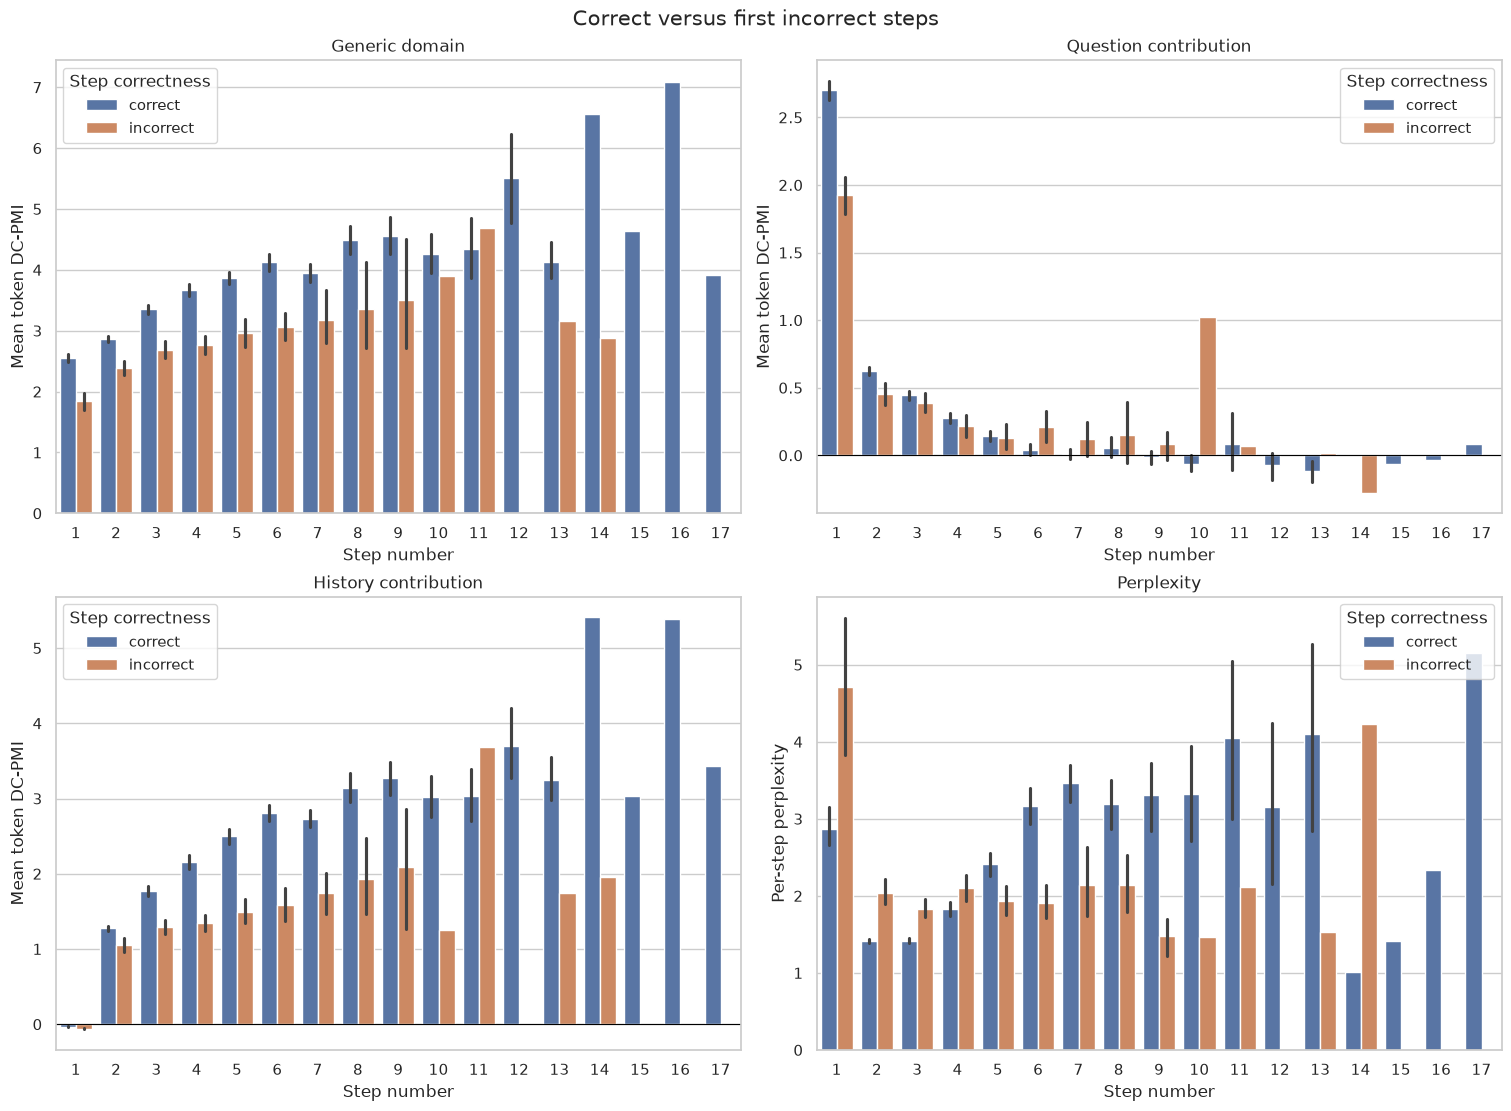

In [11]:
wrong_solution = step_scores["model_output_solution_correctness"].eq("wrong")
first_error_step = pd.to_numeric(
    step_scores["model_output_solution_first_error_step"], errors="coerce"
)
assert first_error_step[wrong_solution].notna().all()
assert (first_error_step[wrong_solution] % 1 == 0).all()

first_error = wrong_solution & step_scores["step"].eq(first_error_step)
assert first_error.groupby(step_scores["uuid"]).sum()[wrong_solution.groupby(step_scores["uuid"]).any()].eq(1).all()

step_scores["step_correctness"] = "correct"
step_scores.loc[first_error, "step_correctness"] = "incorrect"
step_scores.loc[
    wrong_solution & step_scores["step"].gt(first_error_step),
    "step_correctness",
] = pd.NA
labeled_step_scores = step_scores.dropna(subset=["step_correctness"]).copy()

sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)
for ax, (column, title) in zip(axes.flat, METRICS.items()):
    sns.barplot(
        data=labeled_step_scores,
        x="step",
        y=column,
        hue="step_correctness",
        hue_order=["correct", "incorrect"],
        errorbar=("ci", 95),
        ax=ax,
    )
    if column != "perplexity":
        ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Step number")
    ax.set_ylabel("Per-step perplexity" if column == "perplexity" else "Mean token DC-PMI")
    ax.legend(title="Step correctness")
fig.suptitle("Correct versus first incorrect steps", fontsize=15)
plt.show()

## First-error classification

Low DC-PMI is treated as evidence of an error, whereas high perplexity is treated as evidence of an error.

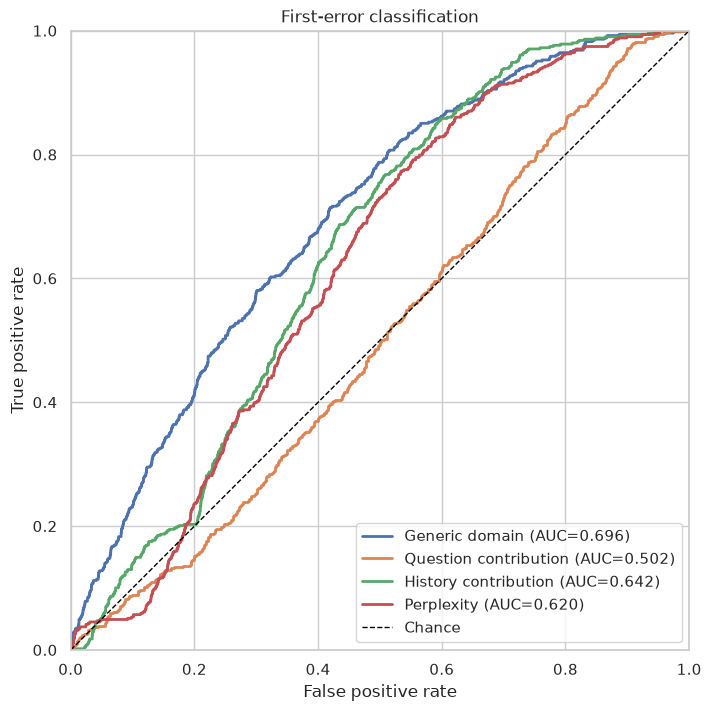

,metric,roc_auc
0,Generic domain,0.695862
2,History contribution,0.642498
3,Perplexity,0.619681
1,Question contribution,0.502194


In [12]:
false_step = labeled_step_scores["step_correctness"].eq("incorrect").astype(int)
assert false_step.nunique() == 2

fig, ax, roc_table = plot_first_error_roc(
    false_step,
    {
        title: ERROR_SCORE_DIRECTIONS[column] * labeled_step_scores[column]
        for column, title in METRICS.items()
    },
)
plt.show()
display(roc_table.sort_values("roc_auc", ascending=False))

## Scores around the first error

Wrong solutions are aligned so that relative step 0 is the annotated first error. Later steps are shown only to visualize the trajectory; they are not treated as independently incorrect.

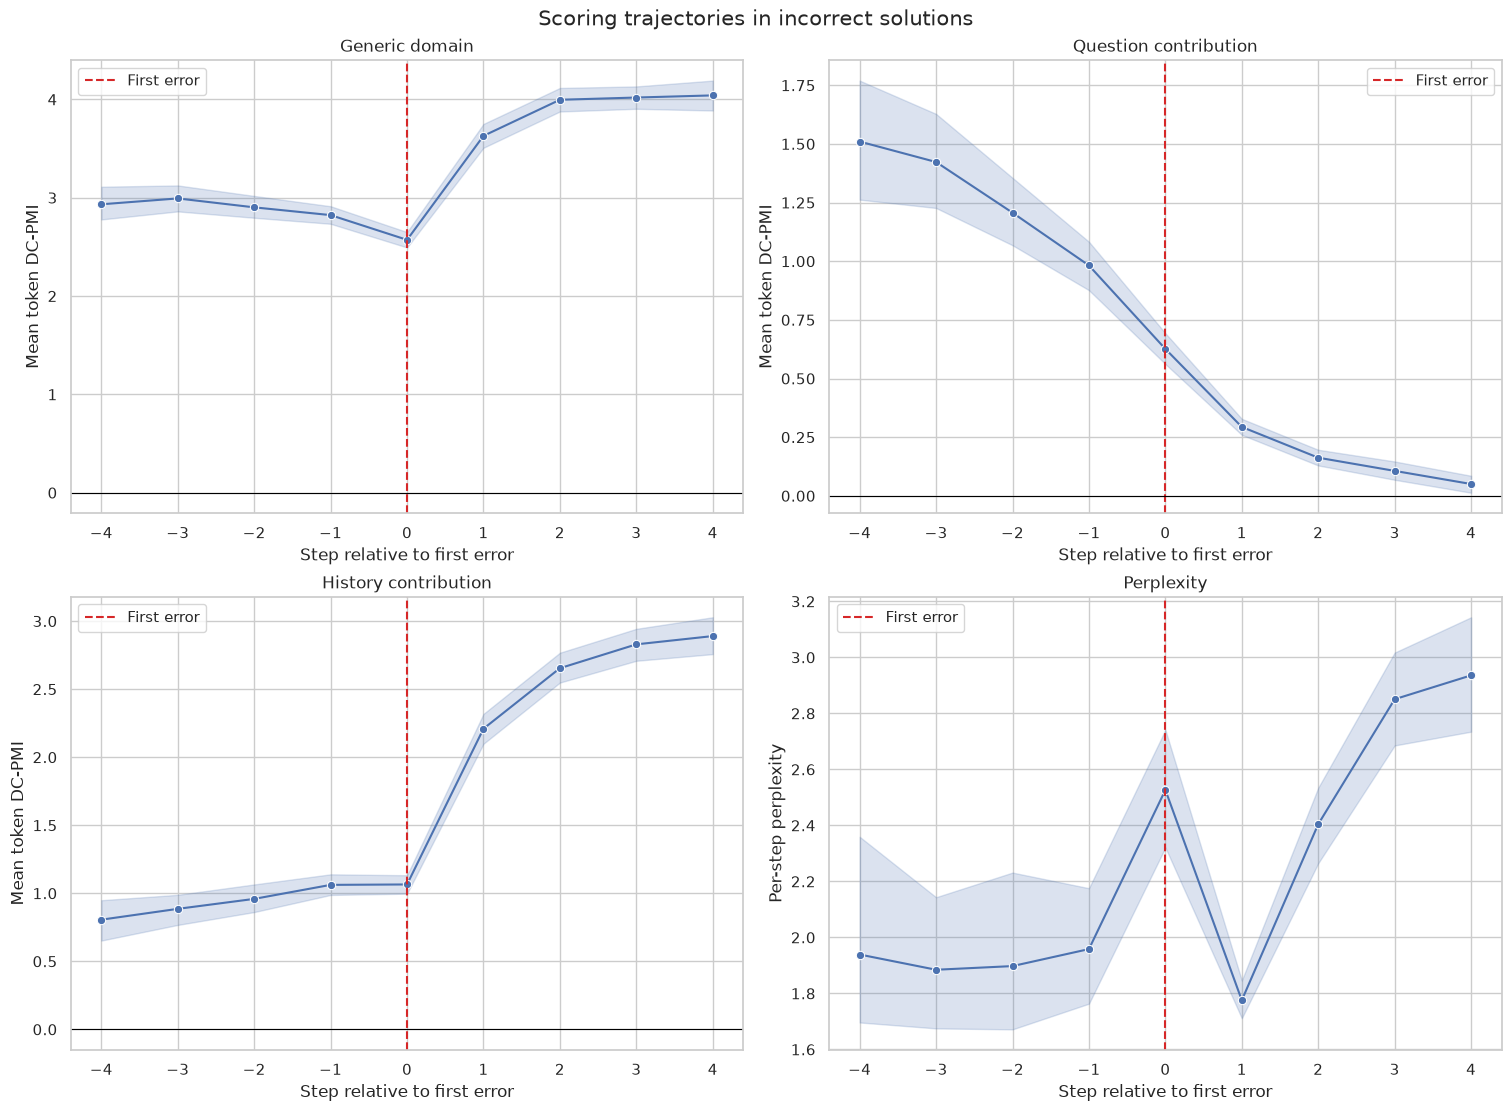

In [13]:
wrong_step_scores = align_first_error_steps(step_scores, window=int(step_scores["step"].max()))
fig, axes = plot_first_error_trajectories(
    step_scores, METRICS,
    window=ERROR_CLIFF_WINDOW,
    title="Scoring trajectories in incorrect solutions",
    ylabels={
        column: "Per-step perplexity" if column == "perplexity" else "Mean token DC-PMI"
        for column in METRICS
    },
    zero_line=set(METRICS) - {"perplexity"},
    figsize=(15, 11),
)
plt.show()

## First differences around the first error

For each incorrect solution, the first difference at step $i$ is its score at step $i$ minus its score at step $i-1$. Step 0 is the annotated first error; solutions whose first error is at step 1 have no difference at 0. Later steps show the trajectory, not additional independently labeled errors.

In [14]:
wrong_step_scores

,sample_index,uuid,question_type,ground_truth_answer,model_output_answer_correctness,model_output_solution_correctness,model_output_solution_first_error_step,model_output_solution_first_error_reason,step,text,...,history_ablated_average_log_likelihood,history_ablated_log_likelihood,tokens,average_log_likelihood,dc_pmi_generic_domain,dc_pmi_question_ablation,dc_pmi_history_ablation,perplexity,step_correctness,relative_step
21,2,0a71e234-b79c-4ace-944b-d0294c0f69db,original,20,wrong,wrong,1.0,"Even though they agree to split the fence, the...",1,Step 1: We know that Sam and Harry agreed to ...,...,-2.667841,-101.377975,38,-2.780046,0.614023,0.702267,-0.112205,16.119766,incorrect,0
22,2,0a71e234-b79c-4ace-944b-d0294c0f69db,original,20,wrong,wrong,1.0,"Even though they agree to split the fence, the...",2,Step 2: We also know that Harry got 60 feet mo...,...,-2.619515,-102.161079,39,-0.560728,3.029597,0.373057,2.058787,1.751948,NaN,1
23,2,0a71e234-b79c-4ace-944b-d0294c0f69db,original,20,wrong,wrong,1.0,"Even though they agree to split the fence, the...",3,Step 3: That means Sam got 50-110 = <<50-110=6...,...,-4.047776,-105.242188,26,-1.029296,4.568736,0.067447,3.018480,2.799095,NaN,2
24,2,0a71e234-b79c-4ace-944b-d0294c0f69db,original,20,wrong,wrong,1.0,"Even though they agree to split the fence, the...",4,Step 4: #### 60,...,-5.612723,-39.289062,7,-0.863937,5.620439,0.148890,4.748786,2.372484,NaN,3
25,3,b9955a63-18a0-4a4a-9440-0b97a73558f2,original,2,wrong,wrong,5.0,"Misunderstanding, the same quantity of chamomi...",1,Step 1: Lana has 27 cups in total.,...,-0.659580,-7.914955,12,-0.759637,4.501533,4.794808,-0.100057,2.137500,correct,-4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7007,999,011f88a5-9cec-495f-819f-bcd8d92a5efc,original,180,wrong,wrong,4.0,"The calculation is incorrect, (150+130+260)/3=...",2,"Step 2: If Bob weighs twice as much as Susan, ...",...,-2.244174,-58.348537,26,-0.208341,2.760743,0.367875,2.035833,1.231634,correct,-2
7008,999,011f88a5-9cec-495f-819f-bcd8d92a5efc,original,180,wrong,wrong,4.0,"The calculation is incorrect, (150+130+260)/3=...",3,Step 3: To find the average weight of the 3 fr...,...,-1.458712,-37.926517,26,-0.177694,2.389995,0.672788,1.281018,1.194459,correct,-1
7009,999,011f88a5-9cec-495f-819f-bcd8d92a5efc,original,180,wrong,wrong,4.0,"The calculation is incorrect, (150+130+260)/3=...",4,Step 4: So the average weight is (150 + 130 + ...,...,-1.812541,-58.001312,32,-0.971677,2.045344,-0.169389,0.840864,2.642371,incorrect,0
7010,999,011f88a5-9cec-495f-819f-bcd8d92a5efc,original,180,wrong,wrong,4.0,"The calculation is incorrect, (150+130+260)/3=...",5,Step 5: #### 140,...,-4.884766,-34.193363,7,-0.453281,6.189577,0.223678,4.431485,1.573466,NaN,1


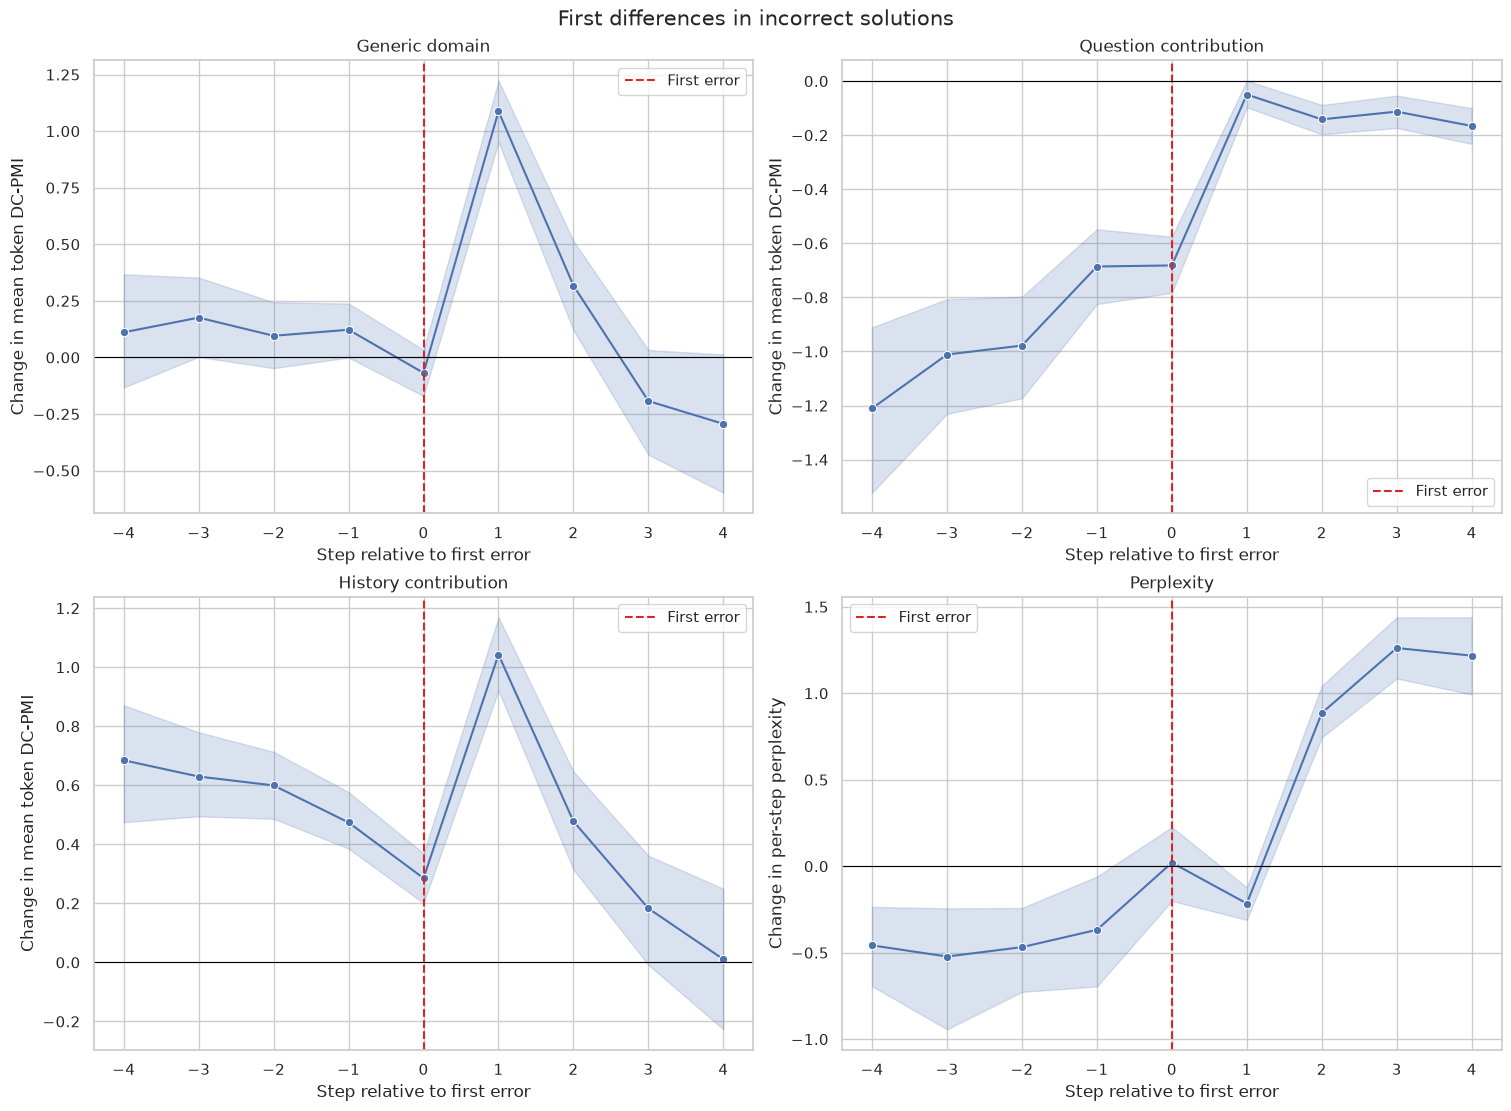

In [15]:
difference_scores = compute_first_differences(wrong_step_scores, METRICS)
difference_columns = {f"{column}_first_difference": title for column, title in METRICS.items()}
fig, axes = plot_first_error_trajectories(
    difference_scores, difference_columns,
    window=ERROR_CLIFF_WINDOW,
    title="First differences in incorrect solutions",
    ylabels={
        f"{column}_first_difference": (
            "Change in per-step perplexity" if column == "perplexity" else "Change in mean token DC-PMI"
        )
        for column in METRICS
    },
    figsize=(15, 11),
)
plt.show()